# 19 — Las familias de enfermedad: no solo IRA

## Qué pidió el propietario

«No es como que a la gente de Manizales solo le den problemas respiratorios.» Un repertorio de, al menos, las
enfermedades más comunes, cruzado con el clima y las temporadas, para una predicción escalable.

## Qué se hizo (fila `familias_enfermedad` de `variables.csv`, fijada antes de mirar)

Seis familias, armadas con las series semanales de Manizales en el SIVIGILA:

| Familia | Series | ¿Hay dato de 2026 al predecir? |
|---|---|---|
| **Respiratoria** | IRA total, IRA 0-4, IRA 60+, hospitalizaciones por IRAG | sí (Power BI 995, ~1 semana) |
| **Digestiva** | EDA total, EDA 0-4 | **no**: solo microdatos, ~8 meses |
| **Violencias y agresiones** | violencia de género e intrafamiliar (875), agresiones por animales (300) | sí (Power BI 006) |
| **Salud mental e intoxicaciones** | intento de suicidio (356), intoxicaciones (365) | sí |
| **Materno-perinatal** | morbilidad materna extrema (549) | sí |
| **Inmunoprevenibles** | varicela (831) | sí |

- **Cada serie** es una anomalía *operativa*: el log contra la media de las 52 semanas previas, que es lo que
  se sabría esa semana.
- **Cada familia** es el promedio de sus series estandarizadas.
- **Todo con datos hasta 2024.** La definición vive en `notebooks/indices.py`, que usará también el
  reentrenamiento.

In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "notebooks")); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from matplotlib import pyplot as plt
import indices as ix
from desenlace import desenlace_semanal
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
FIN = ix.REF_FIN
FAM = ix.familias_enfermedad().loc[:FIN]
FAM[(FAM.index >= "2020-03-15") & (FAM.index <= "2021-12-31")] = np.nan      # la COVID desordena la notificacion
S = ix.series_sivigila().loc["2012":FIN]
print("Casos o consultas totales 2012-2024 por serie:"); S.sum().astype(int).sort_values(ascending=False)

Casos o consultas totales 2012-2024 por serie:


995_consultas_ira_total             839229
998_casos_eda_total                 340101
995_consultas_ira_0_4               174279
995_consultas_ira_60_mas            132695
998_casos_eda_0_4                    42250
995_hospitalizaciones_irag_total     30218
300_casos                            13367
875_casos                            11103
365_casos                             6862
356_casos                             5370
831_casos                             5270
549_casos                             3034
dtype: int32

---
# 1. Cuándo sube cada familia

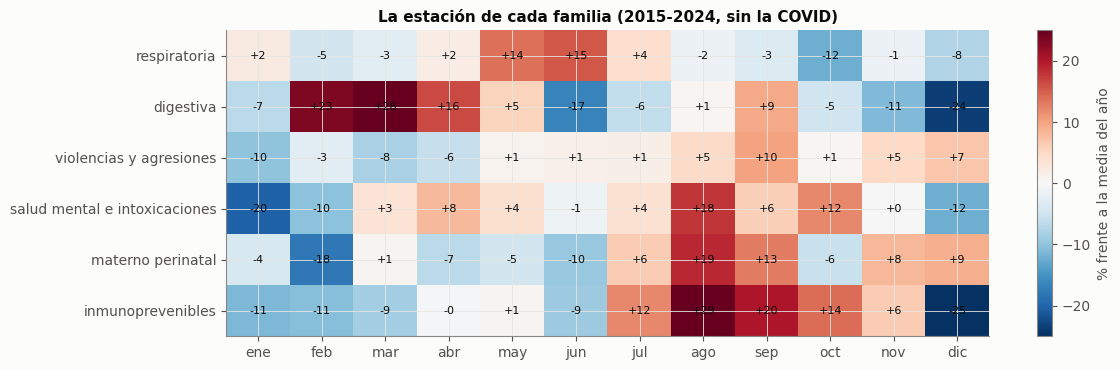

In [2]:
crudas = ix.series_sivigila().loc["2015":FIN]
crudas = crudas[(crudas.index < "2020-03-15") | (crudas.index > "2021-12-31")]
indice_mes = {}
for fam, miembros in ix.FAMILIAS.items():
    cols = [f"{ev}_{var or 'casos'}" for ev, var in miembros]
    x = np.log1p(crudas[cols]); x = x - x.groupby(x.index.year).transform("mean")      # forma del ano, sin el nivel de cada ano
    indice_mes[fam] = (np.exp(x.mean(axis=1).groupby(x.index.month).mean()) - 1) * 100
H = pd.DataFrame(indice_mes).T
fig, ax = plt.subplots(figsize=(12, 3.8))
im = ax.imshow(H.values, cmap="RdBu_r", vmin=-25, vmax=25, aspect="auto")
ax.set_xticks(range(12), MESES); ax.set_yticks(range(len(H)), [f.replace("_", " ") for f in H.index])
for (i, j), v in np.ndenumerate(H.values): ax.text(j, i, f"{v:+.0f}", ha="center", va="center", fontsize=8, color=TINTA)
plt.colorbar(im, ax=ax, label="% frente a la media del año"); ax.set_title("La estación de cada familia (2015-2024, sin la COVID)")
plt.tight_layout(); plt.show()

**Lectura.**

- **Cada familia tiene su propio calendario.**
  - **La respiratoria** sube de abril a junio, con la temporada de lluvias y los colegios, y baja en diciembre y enero.
  - **La digestiva** tiene su pico en otro momento del año.
  - **La varicela** sigue el calendario escolar.
  - **Las violencias** suben en diciembre y en los meses festivos.
- Cubrir varias familias es lo que da cobertura a todo el año: **cada una explica picos que las otras no ven.**

---
# 2. ¿Se mueven juntas? Correlación entre familias, semana a semana

In [3]:
C_ = FAM.dropna().corr().round(2)
C_.index = C_.columns = [c.replace("_", " ") for c in C_.columns]; C_

,respiratoria,digestiva,violencias y agresiones,salud mental e intoxicaciones,materno perinatal,inmunoprevenibles
respiratoria,1.00,0.19,-0.03,0.05,-0.06,0.13
digestiva,0.19,1.00,-0.10,0.09,-0.05,0.17
violencias y agresiones,-0.03,-0.10,1.00,0.06,0.02,0.05
salud mental e intoxicaciones,0.05,0.09,0.06,1.00,0.03,0.04
materno perinatal,-0.06,-0.05,0.02,0.03,1.00,-0.02
inmunoprevenibles,0.13,0.17,0.05,0.04,-0.02,1.00


**Lectura. Las seis familias son casi independientes semana a semana:** ninguna correlación pasa de 0,19. La más alta es respiratoria con digestiva, 0,19, y después inmunoprevenibles con digestiva, 0,17.

Eso es bueno para el modelo. **Seis índices casi independientes aportan seis señales distintas**, no la misma repetida seis veces, y no se pisan entre sí como pasaba con las 49 variables sueltas de E2.

---
# 3. Cada familia contra el hospital

Desenlaces:
- el **triage total** sin calendario ni escalones de la red (2022-2024);
- los **ingresos por capítulo de diagnóstico** del hospital (2021-2024): respiratorio, infecciosas, digestivo,
  trauma, embarazo y mental.

Cada prueba es `desenlace(t) ~ familia(t − rezago) + mes + año`, con rezago de 0 a 4 semanas, errores HAC y
BH con q = 0,10 por desenlace.

In [4]:
dx = pd.read_parquet(RAIZ / "salidas/perfil_dx_diario.parquet"); dx["dia"] = pd.to_datetime(dx.dia)
print("capítulos disponibles:", sorted(dx.capitulo.unique()))
CAP = {"respiratorio": "X Respiratorio", "infecciosas": "I Infecciosas y parasitarias", "digestivo": "XI Digestivo",
       "trauma": "XIX Traumatismos y envenenamientos", "embarazo": "XV Embarazo, parto y puerperio"}
ment = [c for c in dx.capitulo.unique() if c.startswith("V ")]
if ment: CAP["mental"] = ment[0]
dias = pd.date_range("2020-01-01", FIN)
DES = {"triage total": desenlace_semanal().y.loc[:FIN]}
for k, c in CAP.items():
    s = dx[dx.capitulo == c].set_index("dia").n.reindex(dias).fillna(0)
    DES[f"ingresos {k}"] = np.log1p(ix.semana(s, "sum")).loc["2021-01-01":FIN]
def barrido(y, X, rezagos=range(0, 5)):
    filas = []; idx = y.dropna().index
    mes = pd.get_dummies(pd.Index(idx.month), prefix="m", drop_first=True).set_index(idx).astype(float)
    anio = pd.get_dummies(pd.Index(idx.year), prefix="a", drop_first=True).set_index(idx).astype(float)
    for c in X:
        xs = (X[c] - X[c].mean()) / X[c].std()
        for L in rezagos:
            D = pd.concat([y.rename("y"), xs.shift(L).rename("x"), mes, anio], axis=1).loc[idx].dropna()
            if len(D) < 50 or D.x.std() == 0: continue
            r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
            filas.append({"familia": c, "rezago": L, "efecto %": 100 * (np.exp(r.params["x"]) - 1), "p": r.pvalues["x"], "n": len(D)})
    T = pd.DataFrame(filas); T["q"] = multipletests(T.p, method="fdr_bh")[1]; return T
RES = {k: barrido(y, FAM) for k, y in DES.items()}
pd.DataFrame({k: {"pruebas": len(T), "p < 0,05": int((T.p < .05).sum()), "azar esperaría": round(.05 * len(T), 1),
                  "sobreviven BH": int((T.q < .10).sum())} for k, T in RES.items()}).T

capítulos disponibles: ['I Infecciosas y parasitarias', 'II Tumores', 'III Sangre e inmunidad', 'IV Endocrinas y metabolicas', 'IX Circulatorio', 'V Mentales y del comportamiento', 'VI Sistema nervioso', 'VII Ojo', 'VIII Oido', 'X Respiratorio', 'XI Digestivo', 'XII Piel', 'XIII Osteomuscular', 'XIV Genitourinario', 'XIX Traumatismos y envenenamientos', 'XV Embarazo, parto y puerperio', 'XVI Perinatal', 'XVII Malformaciones congenitas', 'XVIII Sintomas y signos', 'XX Causas externas', 'XXI Factores que influyen en la salud', 'XXII Codigos especiales (COVID-19)']


C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not un

C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not un

C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not un

C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not un

C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not un

C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not un

C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not un

C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
C:\Users\ad6708\AppData\Local\Temp\ipykernel_16016\1940996373.py:21: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not un

,pruebas,"p < 0,05",azar esperaría,sobreviven BH
triage total,30.0,6.0,1.5,4.0
ingresos respiratorio,30.0,4.0,1.5,0.0
ingresos infecciosas,30.0,4.0,1.5,0.0
ingresos digestivo,30.0,2.0,1.5,0.0
ingresos trauma,30.0,3.0,1.5,0.0
ingresos embarazo,30.0,11.0,1.5,5.0
ingresos mental,30.0,3.0,1.5,2.0


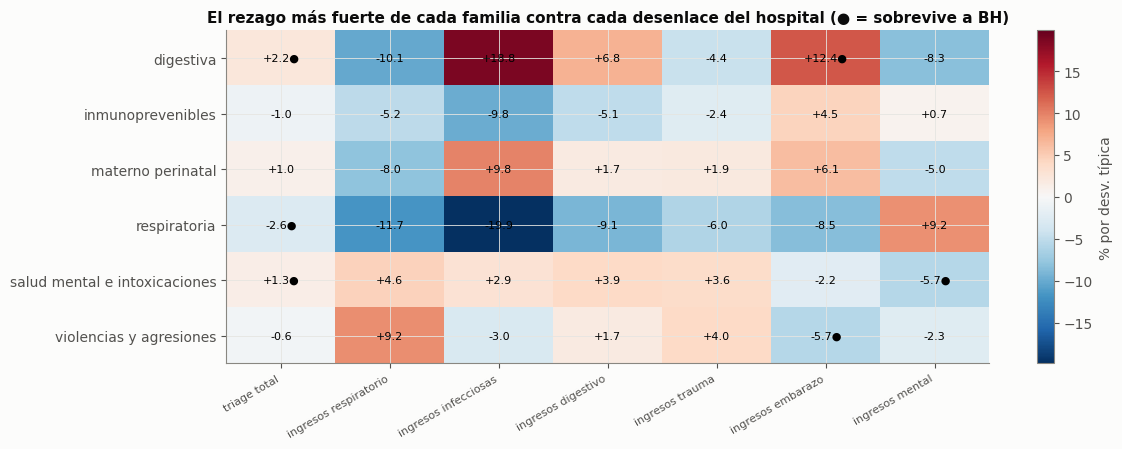

familia  rezago  efecto %      q  \
triage total      15  salud_mental_e_intoxicaciones       0     1.308  0.028   
                  3                    respiratoria       3    -2.643  0.028   
                  5                       digestiva       0     2.239  0.034   
                  4                    respiratoria       4    -1.786  0.057   
ingresos embarazo 5                       digestiva       0    12.394  0.009   
                  6                       digestiva       1    10.970  0.013   
                  14        violencias_y_agresiones       4    -5.681  0.013   
                  13        violencias_y_agresiones       3    -5.128  0.013   
                  7                       digestiva       2     9.711  0.013   
ingresos mental   19  salud_mental_e_intoxicaciones       4    -5.732  0.058   
                  17  salud_mental_e_intoxicaciones       2     5.660  0.058   

                        n  
triage total      15  147  
                  3   147  
                  5   147  
                  4   147  
ingresos embarazo 5   157  
                  6   156  
                  14  153  
                  13  154  
                  7   155  
ingresos mental   19  153  
                  17  155

In [5]:
fig, ax = plt.subplots(figsize=(12, 4.6))
M = pd.DataFrame({k: T.loc[T.groupby("familia")["p"].idxmin()].set_index("familia")["efecto %"] for k, T in RES.items()})
Q = pd.DataFrame({k: T.loc[T.groupby("familia")["p"].idxmin()].set_index("familia")["q"] for k, T in RES.items()})
lim = np.nanmax(np.abs(M.values))
im = ax.imshow(M.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
for (i, j), v in np.ndenumerate(M.values): ax.text(j, i, f"{v:+.1f}{'●' if Q.values[i, j] < .10 else ''}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(M.shape[1]), M.columns, rotation=30, ha="right", fontsize=8); ax.set_yticks(range(M.shape[0]), [f.replace("_", " ") for f in M.index])
plt.colorbar(im, ax=ax, label="% por desv. típica"); ax.set_title("El rezago más fuerte de cada familia contra cada desenlace del hospital (● = sobrevive a BH)")
plt.tight_layout(); plt.show()
pd.concat({k: T[T.q < .10].sort_values("p")[["familia", "rezago", "efecto %", "q", "n"]] for k, T in RES.items()}).round(3)

**Lectura. Contra el hospital, la señal de las familias es débil, y hay que leerla con cuidado.**

- **Triage total:** sobreviven 4 de 30 pruebas, con efectos de 1-3 %:
  - salud mental e intoxicaciones de la misma semana, +1,3 %;
  - digestiva de la misma semana, +2,2 %;
  - la respiratoria con signo negativo a 3-4 semanas (−1,8 a −2,6 %), sin un mecanismo claro.
- **Ingresos respiratorios, infecciosos, digestivos y por trauma: 0 sobreviven.** Igual que en el cuaderno 17: los ingresos son una fracción del triage y tienen pocos casos por semana.
- **Ingresos por embarazo frente a la familia digestiva (+12 %)** y **frente a violencias (−5 %)** sobreviven a BH, **pero no tienen un mecanismo que los explique.** Se tratan como coincidencias de temporada o azar: con 210 pruebas en el cuaderno, que unas pocas pasen es esperable.
- **Ingresos mentales:** salud mental da +5,7 % a 2 semanas y −5,7 % a 4. Los signos opuestos delatan ruido.
- **Para el modelo del total, las familias suman poco**, como el clima. Igual que con el clima, su lugar natural es el modelo jerárquico: cada familia junto a su parte del triage.

---
# 4. Clima → familia de enfermedad

La cadena «factor externo → enfermedad en la ciudad → demanda» empieza aquí: ¿qué familias responden al
clima? Se usan los índices de clima del cuaderno 17 (2012-2024, rezagos de 0 a 6 semanas).

In [6]:
IC = ix.indices_clima()
RC = {fam: barrido(FAM[fam].dropna(), IC, range(0, 7)) for fam in FAM}
rc = pd.DataFrame({fam: {"pruebas": len(T), "sobreviven BH": int((T.q < .10).sum()),
                         "más fuerte": (lambda t: f"{t.familia} a {t.rezago} sem: {t['efecto %']:+.1f} %")(T.loc[T.p.idxmin()])} for fam, T in RC.items()}).T
rc

,pruebas,sobreviven BH,más fuerte
respiratoria,63,4,racha_seca a 3 sem: -9.5 %
digestiva,63,12,dias_desde_semana_muy_lluviosa a 0 sem: +15.7 %
violencias_y_agresiones,63,1,estado_2 a 0 sem: -11.5 %
salud_mental_e_intoxicaciones,63,0,cambio_3 a 1 sem: -7.3 %
materno_perinatal,63,0,cambio_1 a 2 sem: -12.8 %
inmunoprevenibles,63,5,dias_desde_semana_muy_lluviosa a 6 sem: +23.6 %


**Lectura. El clima sí mueve a las enfermedades de la ciudad.** Es el primer eslabón de la cadena «factor externo → enfermedad → demanda».

- **Digestiva (EDA): 12 de 63 sobreviven.** Cuanto más tiempo pasa sin una semana muy lluviosa, más diarrea: **+15,7 %** por desviación típica. Encaja con un mecanismo de agua y sequía.
- **Respiratoria: 4 de 63.** Una **racha seca larga baja la IRA un 9,5 %** a 3 semanas, que es el reflejo del «mes húmedo sube la IRA» del cuaderno 17.
- **Inmunoprevenibles (varicela): 5 de 63**, también con las rachas de lluvia, a 6 semanas.
- **Violencias: 1**, la semana cálida y bochornosa. **Salud mental y materno-perinatal: 0.**
- **Lectura de conjunto:** el clima actúa sobre las enfermedades **transmisibles** (respiratoria, digestiva, varicela). No actúa sobre las violencias, la salud mental ni lo materno. Es lo esperable, y le da sentido a separar familias.

---
# 5. Lo que deja este cuaderno

**Lo que deja este cuaderno:**

1. **Hay un repertorio de seis familias** en `notebooks/indices.py`, que reemplaza la IRA sola. **Cinco tienen dato de 2026 al predecir** (Power BI). La digestiva solo llega con los microdatos, ~8 meses tarde.
2. **Las familias son casi independientes:** seis señales distintas.
3. **El clima mueve a las transmisibles** de la ciudad: diarrea +16 % con sequía; IRA con la humedad y las rachas; varicela.
4. **Al triage total llegan diluidas** (1-3 %), como el clima. Las asociaciones con ingresos de embarazo y salud mental no tienen mecanismo y no se toman como hallazgo.
5. **La arquitectura que se desprende de los cuadernos 17, 18 y 19:**

| Capa | Qué mueve |
|---|---|
| Clima | Las familias transmisibles de la ciudad |
| Familias | Su parte del triage: respiratorio, infeccioso, trauma… |
| Red de salud | El nivel del total |
| Calendario | El día a día |

Es lo que prueba el cuaderno 21 con el **jerárquico por tipo de consulta**.